# Branch-adaptive amplitude estimation

A classical controller selects an amplification power from its existing confidence interval. Every new round samples a fresh fixed-size batch from an explicit `A; Q^power; flag measurement` circuit. There is no phase register or controlled-Q. This bounded variant specifies its own confidence allocation/caps; it does not automatically inherit the original IQAE complexity constants. The threshold probability is known and supplies an independent check, not an advantage benchmark.

In [1]:
from pathlib import Path
import sys, os, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if not (root/"src").exists() and (root.parent/"src").exists():
    root = root.parent
if (root/"src").exists():
    sys.path.insert(0,str(root/"src"))
from openquantum.iterative_amplitude_estimation import (
    AdaptiveAEConfig, run_threshold_adaptive,
    build_amplified_trial, adaptive_logical_ledger,
)
from openquantum.qft_qpe import lower_circuit
def display_history(history):
    rows=[]
    for step in history:
        row={key:step[key] for key in ("round","power","multiplier","lobe","increasing","shots","successes","sampling_probability")}
        interval=step["amplitude_interval"]
        row["amplitude_interval"]=[interval["lower"],interval["upper"]] if interval else None
        row["conservative_radius"]=interval["radius"] if interval else None
        rows.append(row)
    display(pd.DataFrame(rows))

n_data, threshold, seed = 2, 1, 314159
config = AdaptiveAEConfig(absolute_error=.02, failure_probability=.01,
                         shots_per_round=256, max_rounds=20,
                         max_power=64, max_total_shots=8192)
result = run_threshold_adaptive(n_data, threshold, config=config, seed=seed)
print({key:value for key,value in result.items() if key != "history"})

{'algorithm': 'fixed-batch branch-adaptive amplitude estimation inspired by IQAE', 'status': 'conclusive', 'cap_reason': None, 'config': {'absolute_error': 0.02, 'failure_probability': 0.01, 'shots_per_round': 256, 'max_rounds': 20, 'max_power': 64, 'max_total_shots': 8192}, 'seed': 314159, 'probability_mode': 'bounded actual Statevector amplified trials', 'known_reference_amplitude': 0.25, 'angle_convention': 't=asin(sqrt(a))/pi in[0,1/2]', 'final_angle_interval': [0.16178721120445447, 0.1758459848161015], 'final_amplitude_interval': {'lower': 0.23684403371612228, 'upper': 0.27537600916709687, 'estimate': 0.25611002144160955, 'radius': 0.01926598772548732, 'radius_fraction': '347065180565717/18014398509481984', 'arithmetic_certificate': 'outward rational sin² enclosure and radius about the reported float'}, 'total_shots': 1024, 'total_Q_calls': 512, 'total_A_or_A_inverse_calls': 2048, 'total_threshold_predicate_or_inverse_calls': 2048, 'total_flag_measurements': 1024, 'confidence_cont

## One actual sampled circuit

Display the first recorded nonzero power if available. It contains actual preparation, repeated Q gates and a final flag measurement. Only data plus flag are live; the data are discarded after readout.

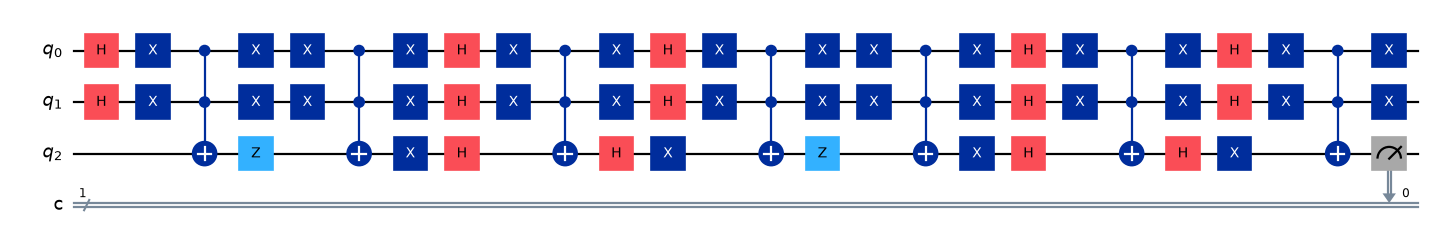

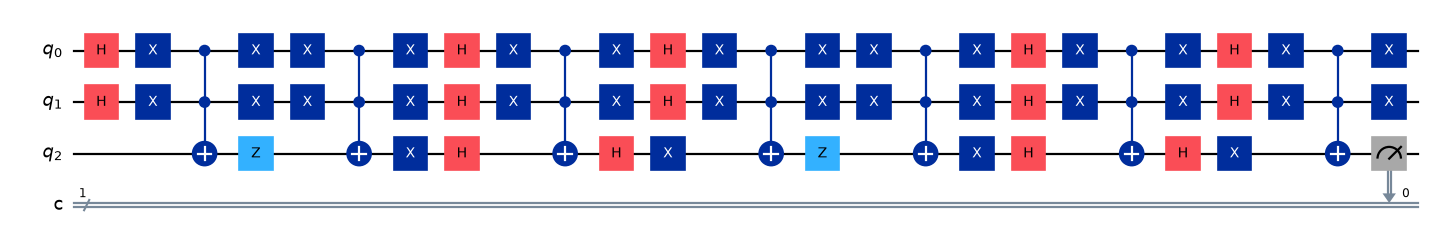

In [2]:
selected_power = next((step["power"] for step in result["history"] if step["power"]>0), 0)
circuit = build_amplified_trial(n_data, threshold, selected_power, measure=True)
circuit.draw(output="mpl", fold=40, scale=.8)

## Every sampled round

Each count is an ideal binomial draw from a bounded statevector probability, independently checked against the amplified sine-squared law. The power is selected from preceding confidence information. Fresh counts are never pooled into a fixed-size interval after optional stopping.

In [3]:
display_history(result["history"])

,round,power,multiplier,lobe,increasing,shots,successes,sampling_probability,amplitude_interval,conservative_radius
0,1,0,1,0,True,256,63,0.25,"[0.159933, 0.349144]",0.094605
1,2,0,1,0,True,256,63,0.25,"[0.159933, 0.349144]",0.094605
2,3,0,1,0,True,256,55,0.25,"[0.159933, 0.314707]",0.077387
3,4,2,5,1,False,256,56,0.25,"[0.236844, 0.275376]",0.019266


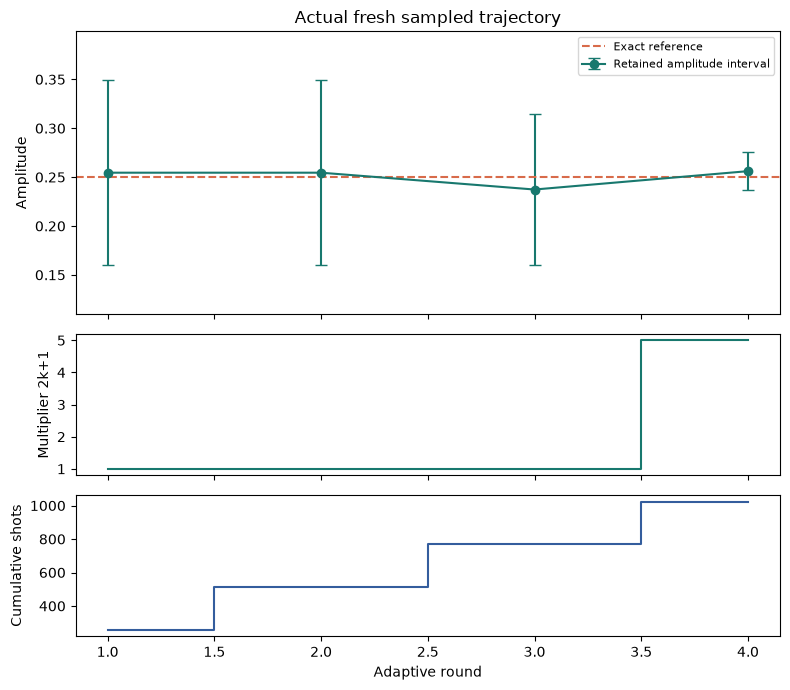

In [4]:
history = result["history"]
intervals = np.array([[step["amplitude_interval"]["lower"],step["amplitude_interval"]["upper"]]
                      if step["amplitude_interval"] else [np.nan,np.nan]
                      for step in history],dtype=float)
rounds = np.arange(1,len(history)+1)
fig,axes = plt.subplots(3,1,figsize=(8,7),sharex=True,
                         gridspec_kw={"height_ratios":[2,1,1]})
axes[0].errorbar(rounds,intervals.mean(axis=1),
                yerr=(intervals[:,1]-intervals[:,0])/2,
                fmt="o-",capsize=4,color="#18786e",label="Retained amplitude interval")
axes[0].axhline(threshold/2**n_data,color="#d86b4a",ls="--",label="Exact reference")
finite=intervals[np.isfinite(intervals).all(axis=1)]
limits=(max(-.03,float(finite[:,0].min())-.05),min(1.03,float(finite[:,1].max())+.05)) if len(finite) else (-.03,1.03)
axes[0].set(ylabel="Amplitude",ylim=limits,title="Actual fresh sampled trajectory")
axes[0].legend(fontsize=8)
axes[1].step(rounds,[2*step["power"]+1 for step in history],where="mid",color="#18786e")
axes[1].set(ylabel="Multiplier 2k+1")
axes[2].step(rounds,np.cumsum([step["shots"] for step in history]),where="mid",color="#345d9d")
axes[2].set(xlabel="Adaptive round",ylabel="Cumulative shots")
fig.tight_layout()
plt.show()

## Complete recorded workload

Every selected shot pays the complete circuit. One trial at power k has one initial A, k further A calls, k inverse-A calls, both reflections k times and one flag readout: 1+2k threshold accesses. A modeled physical projection is conditional on this recorded ideal path; noise can change future choices or stopping.

In [5]:
ledger = adaptive_logical_ledger(n_data, threshold, result)
print(ledger)
print({"recorded_shots_sum":sum(step["shots"] for step in result["history"]),
       "reported_total_shots":result["total_shots"],
       "classical_Hoeffding_shots_same_ideal_target":math.ceil(math.log(2/.01)/(2*.02**2))})
assert sum(step["shots"] for step in result["history"]) == result["total_shots"]

{'status': 'recorded ideal adaptive trajectory; all selected batches charged', 'circuits': [{'power': 0, 'multiplier': 1, 'shots': 768, 'logical_qubits': 3, 'decomposed_gate_counts': {'cx': 6, 't': 4, 'tdg': 3, 'ry': 2, 'h': 2, 'x': 2, 'measure': 1}, 'operations_per_shot': 20, 'dependency_depth_per_shot': 12, 'all_shot_operations': 15360, 'all_shot_dependency_depth': 9216, 'A_calls_per_shot': 1, 'A_inverse_calls_per_shot': 0, 'predicate_or_inverse_calls_per_shot': 1, 'zero_reflections_per_shot': 0, 'good_reflections_per_shot': 0, 'measurements_per_shot': 1}, {'power': 2, 'multiplier': 5, 'shots': 256, 'logical_qubits': 3, 'decomposed_gate_counts': {'cx': 42, 't': 22, 'tdg': 21, 'ry': 16, 'rz': 14, 'h': 2, 'x': 2, 'measure': 1}, 'operations_per_shot': 120, 'dependency_depth_per_shot': 80, 'all_shot_operations': 30720, 'all_shot_dependency_depth': 20480, 'A_calls_per_shot': 3, 'A_inverse_calls_per_shot': 2, 'predicate_or_inverse_calls_per_shot': 5, 'zero_reflections_per_shot': 2, 'good_r

## Ideal confidence and honest caps

With T declared in advance, each new fixed-N binomial interval gets delta/T. Conditional coverage and a union bound give P(conclusive and wrong) <= delta under the exact ideal law. This does not imply P(correct | conclusive) >= 1-delta. A cap can remain inconclusive; The core checks exact rational binomial-tail inequalities, monotone branch conditions, outward trigonometric enclosures and the returned radius. These executed arithmetic certificates are separate from any formal proof of the PRNG or hardware law. The seed and full status remain part of the result.

## Optional bounded local/Binder controls

The public page reuses saved outputs and omits inert widgets. A live kernel can regenerate circuits and trajectories at 1-3 data bits, fixed fresh 128-shot rounds, at most 10 rounds and power 32. It displays inconclusive status without changing the target.

In [6]:
def explore_adaptive(n_data, threshold, absolute_error):
    if not 1 <= n_data <= 3 or not 0 <= threshold <= 2**n_data:
        raise ValueError("Controls permit 1-3 data bits and a valid threshold")
    cfg=AdaptiveAEConfig(absolute_error=absolute_error,failure_probability=.05,
                         shots_per_round=128,max_rounds=10,max_power=32,max_total_shots=1280)
    sampled=run_threshold_adaptive(n_data,threshold,config=cfg,seed=314159)
    print({key:value for key,value in sampled.items() if key != "history"})
    display_history(sampled["history"])

if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    data=widgets.IntSlider(value=2,min=1,max=3,description="Data bits",continuous_update=False)
    threshold_widget=widgets.IntSlider(value=1,min=0,max=4,description="Threshold",continuous_update=False)
    error=widgets.FloatSlider(value=.04,min=.02,max=.1,step=.01,description="Error",continuous_update=False)
    def resize(change):
        threshold_widget.max=2**change["new"]
    data.observe(resize,names="value")
    output=widgets.interactive_output(explore_adaptive,
            {"n_data":data,"threshold":threshold_widget,"absolute_error":error})
    display(widgets.VBox([data,threshold_widget,error,output]))

## Sources and scope

Grinko, Gacon, Zoufal and Woerner, *Iterative quantum amplitude estimation*, npj Quantum Information 7, 52 (2021), DOI 10.1038/s41534-021-00379-1. The fresh-batch branch-adaptive schedule here is an original bounded variant, not an automatic reproduction of their asymptotic constants. Explicit circuits/statevectors use Qiskit core 2.6.2; intervals use SciPy 1.18.1; seeded counts use NumPy 2.5.4. See the chapter’s same-page analysis and verification for full trajectories, validated cases, model-only coverage sweeps, code/license links and conditional resource assumptions. No hardware interval certificate or Lean proof is integrated.